# Bengali Proverb Stereotype — End-to-End Pipeline

এই notebook টা তোমার clean dataset (`clean_1000.csv` অথবা `clean_full_7299.csv`) নিয়ে
ধাপে ধাপে চলে:

1. **Data loading & preprocessing** — বাংলা normalize, label encode
2. **EDA** — class distribution দেখা
3. **Train/val/test split** — stratified
4. **Baseline** — TF-IDF + Logistic Regression / Linear SVM (valence 3-class)
5. **Transformer** — BanglaBERT fine-tune (valence)
6. **Bias / Fairness evaluation** — gender ও category অনুযায়ী performance
7. **Next steps** — LLM eval, figurative metrics

> **প্রথম টাস্ক:** `stereotype_valence` (Negative / Neutral / Positive) predict করা।
> এটা সবচেয়ে clean আর ML-ready। পরে category / gender / figurative-এ যাওয়া যাবে।

**Kaggle setup:** ডান পাশে Settings → Accelerator → **GPU** on করো (BanglaBERT-এর জন্য),
আর Internet **On** করো (model download-এর জন্য)। তারপর dataset টা
'+ Add Input' দিয়ে upload করো।

## ধাপ ০ — Install & Import

In [1]:
# BanglaBERT-এর normalizer (best result-এর জন্য)
!pip install -q git+https://github.com/csebuetnlp/normalizer
!pip install -q transformers datasets scikit-learn seaborn 2>/dev/null

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 12.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [2]:
import os, re, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score)
warnings.filterwarnings('ignore')
sns.set(style='whitegrid')
RANDOM_STATE = 42

## ধাপ ১ — Data Loading & Preprocessing

CSV path টা তোমার Kaggle input অনুযায়ী বদলাও (সাধারণত `/kaggle/input/<dataset-name>/clean_1000.csv`)।

In [3]:
# ---- path বদলাও তোমার Kaggle input অনুযায়ী ----
CSV_PATH = '//kaggle/input/datasets/sumaiyakhan1/dataset1/clean_validated_2210.csv'
# লোকালি টেস্ট করলে: CSV_PATH = 'clean_1000.csv'

df = pd.read_csv(CSV_PATH)
print('row:', len(df), '| columns:', len(df.columns))
df.head(3)

row: 2210 | columns: 17


,id,bangla_proverb,literal_gloss,figurative_meaning,english_translation,is_figurative,gender_relevant,stereotype_target,stereotype_valence,stereotype_category,source_name,source_url,annotator_id,notes,validator,flag_reason,priority
0,22,বাড়ন্তরা অনেক খায়।,বাড়ন্ত বয়সের মানুষেরা অনেক খায়,অল্প বয়সে শরীরের বৃদ্ধির জন্য বেশি খাদ্যের প্...,A growing youth has a wolf in his belly,True,False,তরুণ/কিশোর,Neutral,শারীরিক অবস্থা,English & Bengali Proverbs,https://banglaproverbs.blogspot.com/,azrof,"ঠিক আছে, valence/target/meaning সামঞ্জস্যপূর্ণ...",Sumaiya,NaN,২ পরে
1,23,অনুতপ্ত হলে অভিযোগকারীর প্রয়োজন নেই।,অনুতপ্ত হলে অন্য অভিযোগকারীর প্রয়োজন নেই,অপরাধ স্বীকার করলে অন্যে দোষারোপ না করলেও চলে।,A guilty conscience needs no accuser,True,False,অপরাধী ব্যক্তি,Neutral,নৈতিকতা,English & Bengali Proverbs,https://banglaproverbs.blogspot.com/,azrof,"ঠিক আছে, valence/target/meaning সামঞ্জস্যপূর্ণ...",Sumaiya,NaN,২ পরে
2,24,"ঠাকুর ঘরে কে, আমি তো কলা খাইনি।","ঠাকুরের ঘরে কে আছেন, আমি তো কলা খাইনি",নির্দোষ থাকলেও অন্যায়ভাবে সন্দেহের শিকার হওয়া।,A guilty mind is always suspicious,True,False,নির্দোষ ব্যক্তি,Negative,বিচার/সন্দেহ,English & Bengali Proverbs,https://banglaproverbs.blogspot.com/,azrof,"ঠিক আছে, valence/target/meaning সামঞ্জস্যপূর্ণ...",Sumaiya,NaN,২ পরে


In [4]:
# বাংলা text normalize (NFC + বাড়তি স্পেস সরানো)
try:
    from normalizer import normalize as bn_normalize   # BanglaBERT-এর normalizer
    def clean_bn(s):
        return bn_normalize(str(s))
except Exception:
    def clean_bn(s):
        s = unicodedata.normalize('NFC', str(s))
        return re.sub(r'\s+', ' ', s).strip()

# ML-এর জন্য input text = proverb + figurative meaning
df['text'] = (df['bangla_proverb'].fillna('').map(clean_bn) + ' ' +
              df['figurative_meaning'].fillna('').map(clean_bn)).str.strip()

# label: valence (3-class)
LABELS = ['Negative', 'Neutral', 'Positive']
label2id = {l:i for i,l in enumerate(LABELS)}
id2label = {i:l for l,i in label2id.items()}
df = df[df['stereotype_valence'].isin(LABELS)].reset_index(drop=True)
df['label'] = df['stereotype_valence'].map(label2id)
print('label distribution:', df['stereotype_valence'].value_counts().to_dict())

label distribution: {'Negative': 1016, 'Positive': 731, 'Neutral': 463}


## ধাপ ২ — EDA (class distribution)

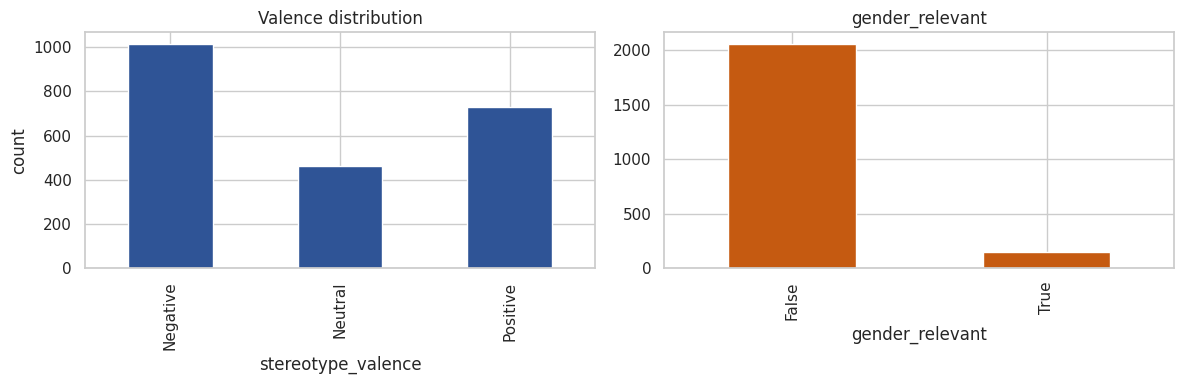

avg words/proverb: 7.6


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
df['stereotype_valence'].value_counts().reindex(LABELS).plot.bar(ax=ax[0], color='#2F5496')
ax[0].set_title('Valence distribution'); ax[0].set_ylabel('count')
df['gender_relevant'].astype(str).value_counts().plot.bar(ax=ax[1], color='#C55A11')
ax[1].set_title('gender_relevant')
plt.tight_layout(); plt.show()

# proverb length (subword-এর আগে একটা ধারণা)
df['n_words'] = df['text'].str.split().apply(len)
print('avg words/proverb:', round(df['n_words'].mean(),1))

## ধাপ ৩ — Train / Validation / Test split (stratified 70/15/15)

In [6]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'],
                                     random_state=RANDOM_STATE)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'],
                                   random_state=RANDOM_STATE)
print('train:', len(train_df), '| val:', len(val_df), '| test:', len(test_df))

train: 1547 | val: 331 | test: 332


## ধাপ ৪ — Baseline: TF-IDF + Logistic Regression / Linear SVM

বাংলার জন্য **character n-gram** TF-IDF ভালো কাজ করে (morphology ধরে ফেলে,
tokenizer লাগে না)।

In [7]:
vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), min_df=2)
Xtr = vec.fit_transform(train_df['text'])
Xva = vec.transform(val_df['text'])
Xte = vec.transform(test_df['text'])

results = {}
for name, model in [
    ('LogReg', LogisticRegression(max_iter=2000, class_weight='balanced')),
    ('LinearSVM', LinearSVC(class_weight='balanced')),
]:
    model.fit(Xtr, train_df['label'])
    pred = model.predict(Xte)
    f1 = f1_score(test_df['label'], pred, average='macro')
    results[name] = f1
    print(f'\n=== {name} ===  Macro-F1 = {f1:.3f}')
    print(classification_report(test_df['label'], pred, target_names=LABELS))


=== LogReg ===  Macro-F1 = 0.672
              precision    recall  f1-score   support

    Negative       0.78      0.75      0.76       153
     Neutral       0.62      0.57      0.59        69
    Positive       0.63      0.70      0.66       110

    accuracy                           0.69       332
   macro avg       0.68      0.67      0.67       332
weighted avg       0.70      0.69      0.69       332


=== LinearSVM ===  Macro-F1 = 0.649
              precision    recall  f1-score   support

    Negative       0.71      0.76      0.73       153
     Neutral       0.61      0.48      0.54        69
    Positive       0.66      0.69      0.68       110

    accuracy                           0.68       332
   macro avg       0.66      0.64      0.65       332
weighted avg       0.67      0.68      0.67       332



In [13]:
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight

# প্রতিটা class-এর weight বের করো (কম-ডেটা class বেশি weight পাবে)
class_weights = compute_class_weight('balanced', classes=np.array([0,1,2]),
                                      y=train_df['label'])
class_weights = torch.tensor(class_weights, dtype=torch.float)
print('class weights:', dict(zip(LABELS, class_weights.tolist())))

# Custom Trainer — loss-এ class weight যোগ করা
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights.to(logits.device))
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss

class weights: {'Negative': 0.7252695560455322, 'Neutral': 1.5915638208389282, 'Positive': 1.0071614980697632}


## ধাপ ৫ — Transformer: BanglaBERT fine-tune

BanglaBERT (`csebuetnlp/banglabert`) বাংলার জন্য সবচেয়ে শক্তিশালী base model।
GPU থাকলে ৩-৪ epoch-এই baseline-কে ছাড়িয়ে যাবে।

In [14]:
import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from datasets import Dataset

MODEL_NAME = 'csebuetnlp/banglabert'
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_hf(d):
    ds = Dataset.from_pandas(d[['text','label']].reset_index(drop=True))
    return ds.map(lambda b: tok(b['text'], truncation=True, max_length=128), batched=True)

train_ds, val_ds, test_ds = to_hf(train_df), to_hf(val_df), to_hf(test_df)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id)

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    return {'macro_f1': f1_score(p.label_ids, preds, average='macro'),
            'accuracy': accuracy_score(p.label_ids, preds)}

args = TrainingArguments(
    output_dir='out', num_train_epochs=6, per_device_train_batch_size=16,
    per_device_eval_batch_size=32, learning_rate=2e-5, weight_decay=0.01,
    eval_strategy='epoch', save_strategy='epoch', load_best_model_at_end=True,
    metric_for_best_model='macro_f1', logging_steps=25, report_to='none')

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=compute_metrics)
trainer.train()

Map:   0%|          | 0/1547 [00:00<?, ? examples/s]

Map:   0%|          | 0/331 [00:00<?, ? examples/s]

Map:   0%|          | 0/332 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['electra.embeddings.LayerNorm.weight', 'electra.embeddings.LayerNorm.bias', 'electra.encoder.layer.0.attention.output.LayerNorm.weight', 'electra.encoder.layer.0.attention.output.LayerNorm.bias', 'electra.encoder.layer.0.output.LayerNorm.weight', 'electra.encoder.layer.0.output.LayerNorm.bias', 'electra.encoder.layer.1.attention.output.LayerNorm.weight', 'electra.encoder.layer.1.attention.output.LayerNorm.bias', 'electra.encoder.layer.1.output.LayerNorm.weight', 'electra.encoder.layer.1.output.LayerNorm.bias', 'electra.encoder.layer.2.attention.output.LayerNorm.weight', 'electra.encoder.layer.2.attention.output.LayerNorm.bias', 'electra.encoder.layer.2.output.LayerNorm.weight', 'electra.encoder.layer.2.output.LayerNorm.bias', 'electra.encoder.layer.3.attention.output.LayerNorm.weight', 'electra.encoder.layer.3.attention.output.LayerNorm.bias', 'electra.encoder.layer.3.output.LayerNorm.weight', 'electra.encoder.layer.3.output.Laye

TrainOutput(global_step=294, training_loss=1.2328537759326754, metrics={'train_runtime': 74.3271, 'train_samples_per_second': 124.88, 'train_steps_per_second': 3.955, 'total_flos': 117377876230146.0, 'train_loss': 1.2328537759326754, 'epoch': 6.0})

In [15]:
# test-এ চূড়ান্ত মূল্যায়ন
pred_out = trainer.predict(test_ds)
bert_pred = np.argmax(pred_out.predictions, axis=1)
print('BanglaBERT Macro-F1:', round(f1_score(test_df['label'], bert_pred, average='macro'),3))
print(classification_report(test_df['label'], bert_pred, target_names=LABELS))

BanglaBERT Macro-F1: 0.771
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88       153
     Neutral       0.66      0.62      0.64        69
    Positive       0.77      0.81      0.79       110

    accuracy                           0.80       332
   macro avg       0.77      0.77      0.77       332
weighted avg       0.80      0.80      0.80       332



## ধাপ ৬ — Bias / Fairness Evaluation

শুধু accuracy না — মডেল **কোন গ্রুপে বেশি ভুল করে** সেটা দেখা তোমার থিসিসের core।

=== gender_relevant অনুযায়ী Macro-F1 ===
  gender_relevant=False | n=307 | Macro-F1=0.774
  gender_relevant=True  | n= 25 | Macro-F1=0.678


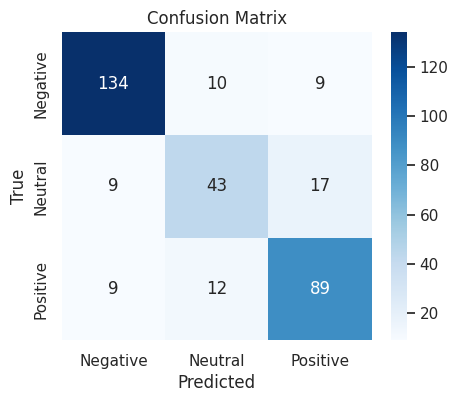

In [16]:
test_eval = test_df.copy()
test_eval['pred'] = bert_pred   # baseline দেখতে চাইলে LogReg-এর pred বসাও

# (ক) gender_relevant অনুযায়ী performance gap
print('=== gender_relevant অনুযায়ী Macro-F1 ===')
for g, sub in test_eval.groupby(test_eval['gender_relevant'].astype(str)):
    if len(sub) >= 5:
        f1 = f1_score(sub['label'], sub['pred'], average='macro')
        print(f'  gender_relevant={g:5} | n={len(sub):3} | Macro-F1={f1:.3f}')

# (খ) confusion matrix
cm = confusion_matrix(test_eval['label'], test_eval['pred'])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=LABELS, yticklabels=LABELS, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix'); plt.show()

In [17]:
# (গ) valence অনুযায়ী error rate — কোন class-এ মডেল দুর্বল
print('=== per-class error rate ===')
for lab in LABELS:
    sub = test_eval[test_eval['stereotype_valence']==lab]
    if len(sub):
        acc = (sub['pred']==sub['label']).mean()
        print(f'  {lab:9} | n={len(sub):3} | accuracy={acc:.3f}')

=== per-class error rate ===
  Negative  | n=153 | accuracy=0.876
  Neutral   | n= 69 | accuracy=0.623
  Positive  | n=110 | accuracy=0.809


## ধাপ ৭ — কী কী পরের ধাপ (তোমার থিসিসের দিকে)

1. **পুরো dataset-এ চালাও** — `clean_full_7299.csv` দিয়ে (1000 → 7299 row, F1 অনেক বাড়বে)।
2. **Category classification** — আগে ৯৮২টা category-কে ৮-১০টা বড় ভাগে সাজাও, তারপর এই একই pipeline।
3. **LLM zero-shot eval** — GPT / Gemini / Llama-কে প্রবাদ দিয়ে জিজ্ঞেস করো (ক) মানে কী, (খ) এতে কোনো দলের প্রতি stereotype আছে কিনা — fine-tuned মডেলের সাথে তুলনা করো।
4. **Figurative vs literal** — literal_gloss আর figurative_meaning আলাদা input দিয়ে মডেল চালিয়ে দেখো কোথায় বেশি bias ধরা পড়ে (তোমার FLBR metric-এর ভিত্তি)।
5. **Fairness metrics** — gender/religion/class সাবগ্রুপে Demographic Parity, Equalized Odds।

**Tip:** প্রতিটা experiment-এর Macro-F1 + subgroup gap একটা টেবিলে রাখো — সেটাই তোমার paper-এর results section।